# Hasil Proyek Klasifikasi Rekomendasi Tanaman

Notebook ini menyajikan hasil evaluasi model **Random Forest** yang sudah dilatih pada proyek utama. Model dibaca dari file `.pkl`, sehingga notebook ini tidak melakukan pelatihan ulang.

Pastikan `Crop_recommendation.csv`, `model_crop_rf.pkl`, dan `label_encoder.pkl` berada di folder yang sama dengan notebook ini. Jalankan seluruh cell dari atas ke bawah.

## 1. Persiapan dan Memuat Artefak

Data uji dibuat ulang dengan pembagian 80:20, stratifikasi berdasarkan kelas, dan `random_state=42` agar hasilnya konsisten dengan notebook utama.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.preprocessing import LabelEncoder

RANDOM_STATE = 42
FITUR = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]

df = pd.read_csv("Crop_recommendation.csv")

if Path("label_encoder.pkl").exists():
    label_encoder = joblib.load("label_encoder.pkl")
else:
    label_encoder = LabelEncoder().fit(df["label"])
    print("label_encoder.pkl tidak ditemukan; encoder dibuat dari label dataset.")

X = df[FITUR]
y = label_encoder.transform(df["label"])
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE,
)
if Path("model_crop_rf.pkl").exists():
    model = joblib.load("model_crop_rf.pkl")
else:
    print("model_crop_rf.pkl tidak ditemukan; Random Forest akan dilatih dengan GridSearchCV.")
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    search = GridSearchCV(
        RandomForestClassifier(random_state=RANDOM_STATE),
        {
            "n_estimators": [100, 200],
            "max_depth": [None, 10, 20],
            "min_samples_split": [2, 5],
        },
        cv=cv,
        scoring="accuracy",
        n_jobs=-1,
    )
    search.fit(X_train, y_train)
    model = search.best_estimator_
    joblib.dump(model, "model_crop_rf.pkl")
    joblib.dump(label_encoder, "label_encoder.pkl")
    print("Model dan label encoder berhasil dilatih dan disimpan.")
    print("Parameter terbaik:", search.best_params_)

y_pred = model.predict(X_test)

print(f"Jumlah data: {len(df):,}")
print(f"Jumlah fitur: {len(FITUR)}")
print(f"Jumlah kelas tanaman: {df['label'].nunique()}")
print(f"Data latih: {len(X_train):,} | Data uji: {len(X_test):,}")
print(f"Missing value: {df.isna().sum().sum()} | Duplikat: {df.duplicated().sum()}")
print(f"Akurasi data uji: {accuracy_score(y_test, y_pred):.4f}")

display(df["label"].value_counts().rename_axis("Tanaman").to_frame("Jumlah data"))

Jumlah data: 2,200
Jumlah fitur: 7
Jumlah kelas tanaman: 22
Data latih: 1,760 | Data uji: 440
Missing value: 0 | Duplikat: 0
Akurasi data uji: 0.9955


,Jumlah data
Tanaman,
rice,100
maize,100
chickpea,100
kidneybeans,100
pigeonpeas,100
mothbeans,100
mungbean,100
blackgram,100
lentil,100


## 2. Classification Report

`Precision` mengukur ketepatan prediksi, `recall` mengukur cakupan data pada setiap kelas, dan `F1-score` merangkum keduanya.

In [2]:
report = classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0,
)
report_df = pd.DataFrame(report).T
display(report_df.round(4))

,precision,recall,f1-score,support
apple,1.0000,1.0000,1.0000,20.0000
banana,1.0000,1.0000,1.0000,20.0000
blackgram,1.0000,0.9500,0.9744,20.0000
chickpea,1.0000,1.0000,1.0000,20.0000
coconut,1.0000,1.0000,1.0000,20.0000
coffee,1.0000,1.0000,1.0000,20.0000
cotton,1.0000,1.0000,1.0000,20.0000
grapes,1.0000,1.0000,1.0000,20.0000
jute,0.9524,1.0000,0.9756,20.0000
kidneybeans,1.0000,1.0000,1.0000,20.0000


## 3. Confusion Matrix

Nilai pada diagonal menunjukkan jumlah prediksi yang benar. Nilai di luar diagonal menunjukkan kelas yang tertukar.

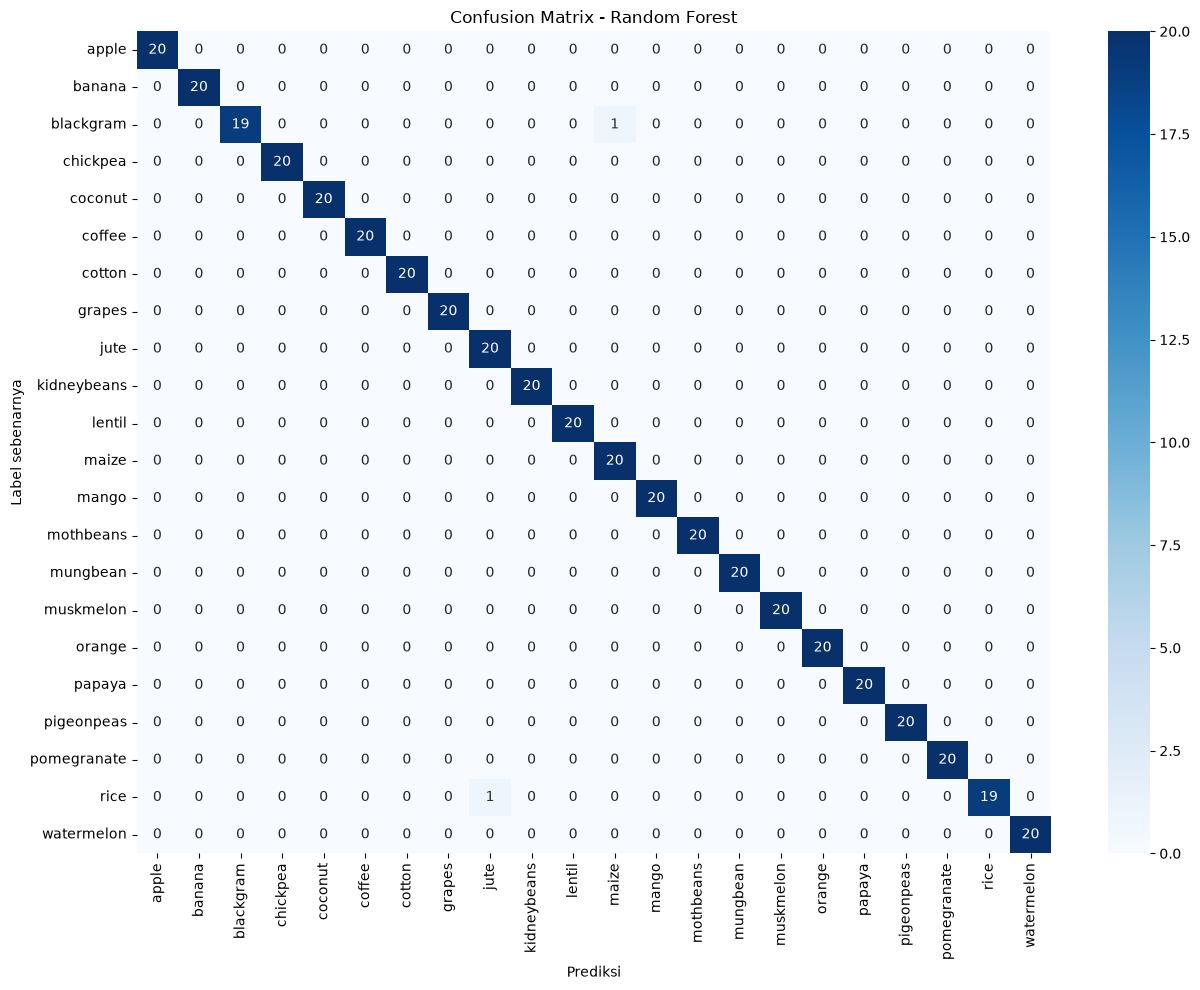

In [3]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_)),
)
plt.figure(figsize=(13, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
)
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Prediksi")
plt.ylabel("Label sebenarnya")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Feature Importance

Grafik berikut memperlihatkan tingkat kepentingan setiap fitur menurut model Random Forest.

,Kepentingan
rainfall,0.220753
humidity,0.220182
K,0.178327
P,0.148808
N,0.106676
temperature,0.074563
ph,0.050691


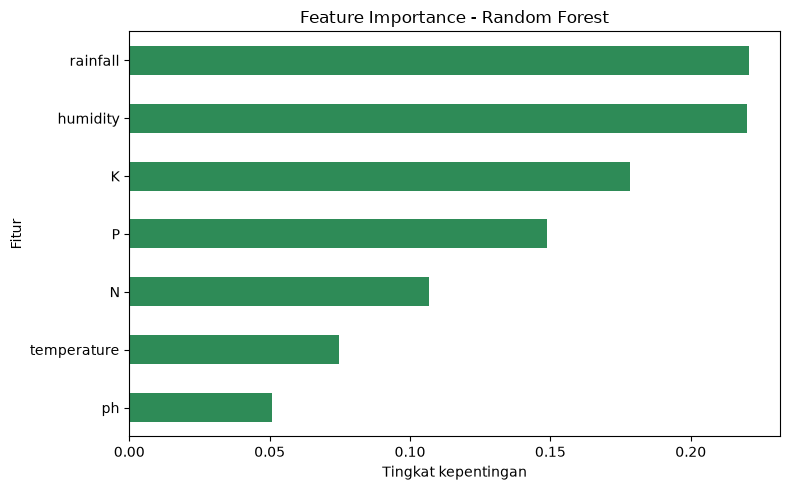

In [4]:
importance = pd.Series(model.feature_importances_, index=FITUR).sort_values()
display(importance.sort_values(ascending=False).rename("Kepentingan").to_frame())

plt.figure(figsize=(8, 5))
importance.plot(kind="barh", color="seagreen")
plt.title("Feature Importance - Random Forest")
plt.xlabel("Tingkat kepentingan")
plt.ylabel("Fitur")
plt.tight_layout()
plt.show()

## 5. Contoh Prediksi

Contoh ini menggunakan kondisi lahan dari notebook utama. Ubah nilai input untuk mencoba kondisi lainnya.

In [5]:
data_baru = pd.DataFrame([{
    "N": 90,
    "P": 42,
    "K": 43,
    "temperature": 20.9,
    "humidity": 82.0,
    "ph": 6.5,
    "rainfall": 202.9,
}])[FITUR]

prediksi = int(model.predict(data_baru)[0])
probabilitas = model.predict_proba(data_baru)[0]
top3_index = np.argsort(probabilitas)[::-1][:3]

print("Rekomendasi tanaman:", label_encoder.inverse_transform([prediksi])[0])
top3 = pd.DataFrame({
    "Tanaman": label_encoder.inverse_transform(top3_index),
    "Probabilitas": probabilitas[top3_index],
})
top3["Probabilitas (%)"] = (top3["Probabilitas"] * 100).round(2)
display(top3[["Tanaman", "Probabilitas (%)"]])

Rekomendasi tanaman: rice


,Tanaman,Probabilitas (%)
0,rice,90.78
1,jute,8.52
2,papaya,0.69


## 6. Kesimpulan

Ringkasan di bawah dihitung langsung dari data uji pada saat notebook dijalankan. Akurasi pada dataset yang bersih dan terkontrol belum tentu sama dengan performa pada kondisi lapangan yang lebih beragam.

In [6]:
akurasi = accuracy_score(y_test, y_pred)
fitur_utama = importance.sort_values(ascending=False).head(3).index.tolist()

print(
    f"Model Random Forest memperoleh akurasi {akurasi:.2%} pada "
    f"{len(X_test):,} data uji dari total {len(df):,} data."
)
print(f"Fitur dengan kepentingan tertinggi: {', '.join(fitur_utama)}.")
print(
    "Hasil ini merupakan evaluasi pada dataset proyek; validasi dengan data "
    "lapangan tetap diperlukan sebelum model digunakan untuk keputusan nyata."
)

Model Random Forest memperoleh akurasi 99.55% pada 440 data uji dari total 2,200 data.
Fitur dengan kepentingan tertinggi: rainfall, humidity, K.
Hasil ini merupakan evaluasi pada dataset proyek; validasi dengan data lapangan tetap diperlukan sebelum model digunakan untuk keputusan nyata.
